In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
from pathlib import Path
import pandas as pd

data_path = Path("C:/Users/judith.osewe/Desktop/Portfolio/Kenya Public Debt/Public Debt (1).csv")

if not data_path.exists():
    raise FileNotFoundError(
        f"Could not find {data_path.name!r} at {data_path.parent}. "
        "Please verify the file path and name."
    )

df = pd.read_csv(data_path)
print(f"Loaded {len(df):,} rows and {len(df.columns)} columns.")
display(df.head())


Loaded 316 rows and 5 columns.


,Year,Month,Domestic_Debt,External_Debt,Total
0,1999,9,183417.00,320137.00,503554.00
1,1999,12,190300.00,311953.00,502253.00
2,2000,3,201463.22,396800.00,598263.22
3,2000,6,206127.00,395694.00,601821.00
4,2000,7,202362.00,394667.37,597029.37


In [3]:
print("Shape:", df.shape)
print("\\nColumn names:", df.columns.tolist())
print("\\nData types:")
display(df.dtypes.to_frame("data_type"))
print("\\nMissing values:")
display(df.isna().sum().to_frame("missing_values"))
print("\\nDuplicate rows:", df.duplicated().sum())
display(df.describe(include="all").T)

Shape: (316, 5)
\nColumn names: ['Year', 'Month', ' Domestic_Debt ', ' External_Debt', ' Total ']
\nData types:


,data_type
Year,int64
Month,int64
Domestic_Debt,float64
External_Debt,float64
Total,float64


\nMissing values:


,missing_values
Year,0
Month,0
Domestic_Debt,0
External_Debt,0
Total,0


\nDuplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Year,316.0,2.012829e+03,7.632173e+00,1999.0,2006.0000,2013.00,2019.000,2026.00
Month,316.0,6.512658e+00,3.458116e+00,1.0,3.7500,6.50,9.250,12.00
Domestic_Debt,316.0,1.897602e+06,1.921508e+06,183417.0,374540.8825,1058118.98,2923547.595,7327202.09
External_Debt,316.0,1.884787e+06,1.804182e+06,311953.0,424914.0725,829252.91,3119679.240,6189967.47
Total,316.0,3.782389e+06,3.709916e+06,502253.0,795463.5400,1866529.76,6036473.110,13097471.11


In [4]:
print("Shape:", df.shape)
print("\\nColumn names:", df.columns.tolist())
print("\\nData types:")
display(df.dtypes.to_frame("data_type"))
print("\\nMissing values:")
display(df.isna().sum().to_frame("missing_values"))
print("\\nDuplicate rows:", df.duplicated().sum())
display(df.describe(include="all").T)

Shape: (316, 5)
\nColumn names: ['Year', 'Month', ' Domestic_Debt ', ' External_Debt', ' Total ']
\nData types:


,data_type
Year,int64
Month,int64
Domestic_Debt,float64
External_Debt,float64
Total,float64


\nMissing values:


,missing_values
Year,0
Month,0
Domestic_Debt,0
External_Debt,0
Total,0


\nDuplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Year,316.0,2.012829e+03,7.632173e+00,1999.0,2006.0000,2013.00,2019.000,2026.00
Month,316.0,6.512658e+00,3.458116e+00,1.0,3.7500,6.50,9.250,12.00
Domestic_Debt,316.0,1.897602e+06,1.921508e+06,183417.0,374540.8825,1058118.98,2923547.595,7327202.09
External_Debt,316.0,1.884787e+06,1.804182e+06,311953.0,424914.0725,829252.91,3119679.240,6189967.47
Total,316.0,3.782389e+06,3.709916e+06,502253.0,795463.5400,1866529.76,6036473.110,13097471.11


In [6]:
df.columns = df.columns.str.strip().str.lower()

# Map the actual CSV column names to your expected names
df = df.rename(columns={
    "domestic_debt": "domestic",
    "external_debt": "external"
})

required_columns = ["year", "month", "domestic", "external", "total"]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

for col in ["year", "month", "domestic", "external", "total"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing values after numeric conversion:")
display(df[required_columns].isna().sum().to_frame("missing_values"))

# Keep rows with valid year and month; debt values remain visible for review.
df = df.dropna(subset=["year", "month"]).copy()
df["year"] = df["year"].astype(int)
df["month"] = df["month"].astype(int)

invalid_months = ~df["month"].between(1, 12)
if invalid_months.any():
    print("Warning: removing rows with invalid month values:")
    display(df.loc[invalid_months, ["year", "month"]])
    df = df.loc[~invalid_months].copy()

df = df.drop_duplicates().sort_values(["year", "month"]).reset_index(drop=True)

# Create a monthly date field.
df["date"] = pd.to_datetime(
    dict(year=df["year"], month=df["month"], day=1),
    errors="coerce"
)
df = df.dropna(subset=["date"]).sort_values("date").reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
display(df.head())


Missing values after numeric conversion:


,missing_values
year,0
month,0
domestic,0
external,0
total,0


Cleaned dataset shape: (316, 6)


,year,month,domestic,external,total,date
0,1999,9,183417.00,320137.00,503554.00,1999-09-01
1,1999,12,190300.00,311953.00,502253.00,1999-12-01
2,2000,3,201463.22,396800.00,598263.22,2000-03-01
3,2000,6,206127.00,395694.00,601821.00,2000-06-01
4,2000,7,202362.00,394667.37,597029.37,2000-07-01


In [7]:
# Debt composition shares. Shares are set to NaN where total is invalid.
valid_total = df["total"] > 0
df["domestic_share"] = np.where(valid_total, df["domestic"] / df["total"] * 100, np.nan)
df["external_share"] = np.where(valid_total, df["external"] / df["total"] * 100, np.nan)

# Changes between consecutive reported observations.
df["total_change"] = df["total"].diff()
df["domestic_change"] = df["domestic"].diff()
df["external_change"] = df["external"].diff()

# Percentage changes between consecutive observations.
df["debt_growth_rate"] = df["total"].pct_change(fill_method=None) * 100
df["domestic_growth"] = df["domestic"].pct_change(fill_method=None) * 100
df["external_growth"] = df["external"].pct_change(fill_method=None) * 100

# Rolling average across 12 observations (not necessarily 12 calendar months if data has gaps).
df["rolling_12_observations"] = df["total"].rolling(window=12, min_periods=12).mean()

print("Feature engineering complete.")
display(df[["date", "total", "domestic_share", "external_share",
            "total_change", "debt_growth_rate"]].head(15))

Feature engineering complete.


,date,total,domestic_share,external_share,total_change,debt_growth_rate
0,1999-09-01,503554.00,36.424495,63.575505,NaN,NaN
1,1999-12-01,502253.00,37.889271,62.110729,-1301.00,-0.258364
2,2000-03-01,598263.22,33.674679,66.325321,96010.22,19.115908
3,2000-06-01,601821.00,34.250550,65.749450,3557.78,0.594685
4,2000-07-01,597029.37,33.894815,66.105185,-4791.63,-0.796189
5,2000-08-01,592294.06,33.190270,66.809730,-4735.31,-0.793145
6,2000-09-01,595318.72,32.842911,67.157089,3024.66,0.510669
7,2000-10-01,595767.03,32.825583,67.174417,448.31,0.075306
8,2000-11-01,596620.45,32.835951,67.164049,853.42,0.143247
9,2000-12-01,598020.61,32.217167,67.782833,1400.16,0.234682


In [8]:
latest = df.dropna(subset=["total"]).iloc[-1]
first = df.dropna(subset=["total"]).iloc[0]

summary = pd.Series({
    "First reporting date": first["date"].strftime("%B %Y"),
    "Latest reporting date": latest["date"].strftime("%B %Y"),
    "First recorded total debt": first["total"],
    "Latest recorded total debt": latest["total"],
    "Absolute change across period": latest["total"] - first["total"],
    "Percentage change across period": (latest["total"] / first["total"] - 1) * 100
})
display(summary.to_frame("value"))

,value
First reporting date,September 1999
Latest reporting date,June 2026
First recorded total debt,503554.0
Latest recorded total debt,13097471.11
Absolute change across period,12593917.11
Percentage change across period,2501.006269


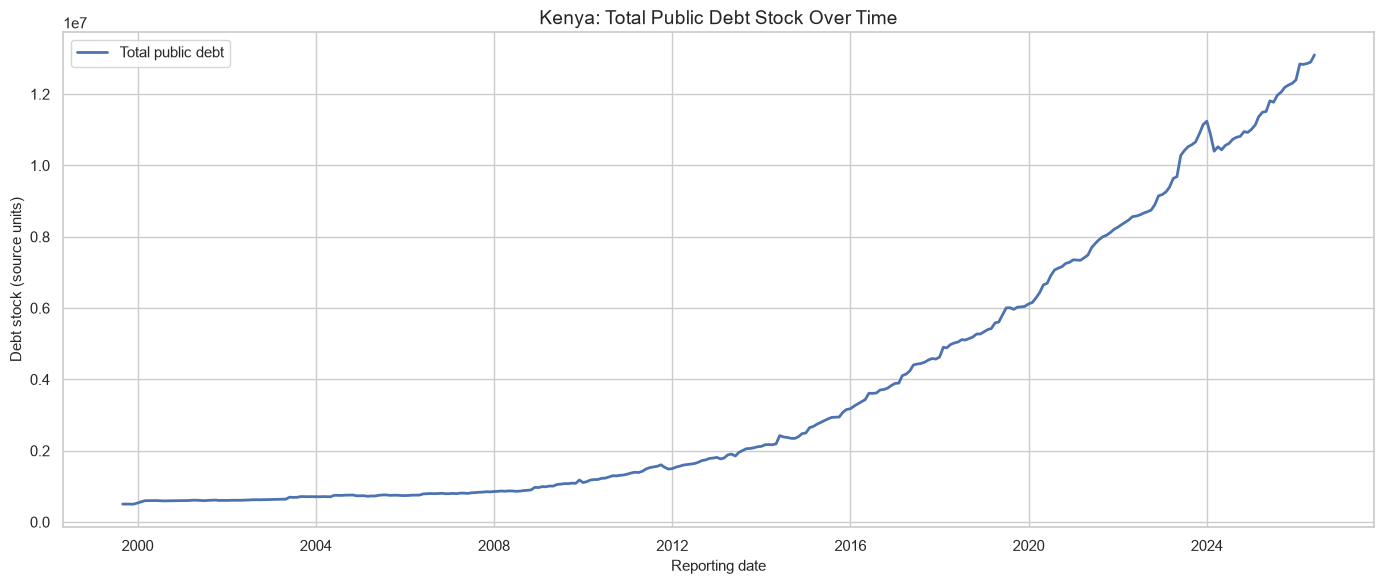

In [9]:
# Graph 1: Total public debt stock over time
fig, ax = plt.subplots()
ax.plot(df["date"], df["total"], linewidth=2, label="Total public debt")
ax.set(title="Kenya: Total Public Debt Stock Over Time", xlabel="Reporting date", ylabel="Debt stock (source units)")
ax.legend()
plt.tight_layout()
plt.show()

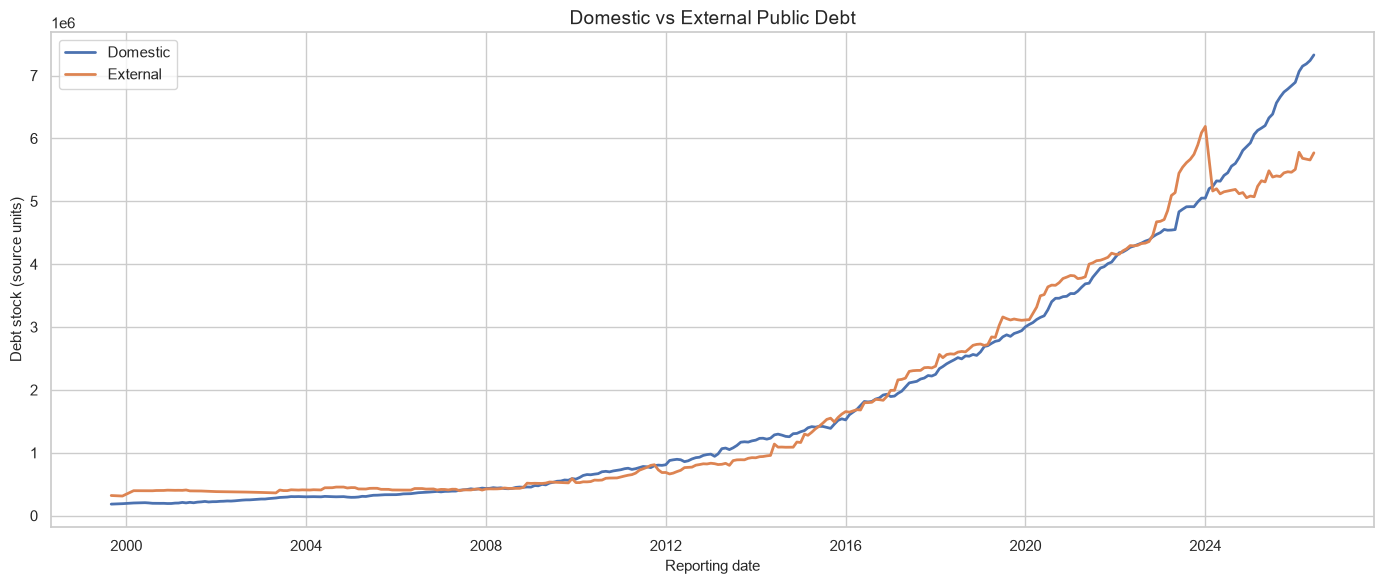

In [10]:
# Graph 2: Domestic vs external debt
fig, ax = plt.subplots()
ax.plot(df["date"], df["domestic"], linewidth=2, label="Domestic")
ax.plot(df["date"], df["external"], linewidth=2, label="External")
ax.set(title="Domestic vs External Public Debt", xlabel="Reporting date", ylabel="Debt stock (source units)")
ax.legend()
plt.tight_layout()
plt.show()

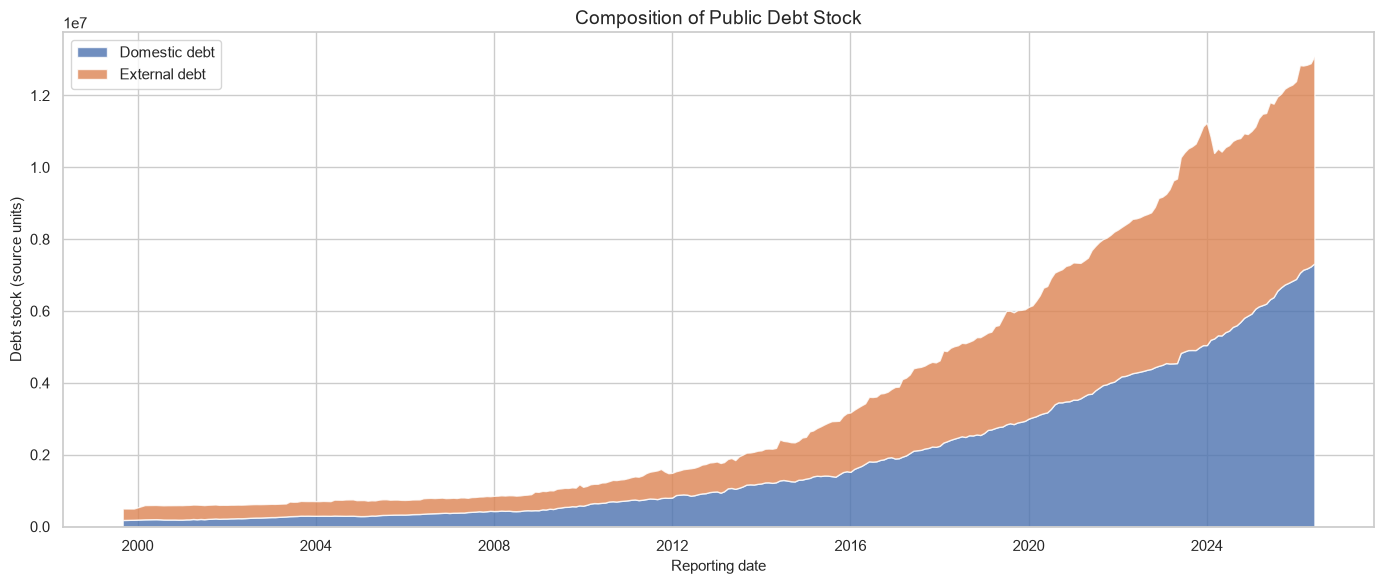

In [11]:
# Graph 3: Stacked area chart of debt composition
plot_df = df.dropna(subset=["domestic", "external"]).sort_values("date")
fig, ax = plt.subplots()
ax.stackplot(plot_df["date"], plot_df["domestic"], plot_df["external"],
             labels=["Domestic debt", "External debt"], alpha=0.8)
ax.set(title="Composition of Public Debt Stock", xlabel="Reporting date", ylabel="Debt stock (source units)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

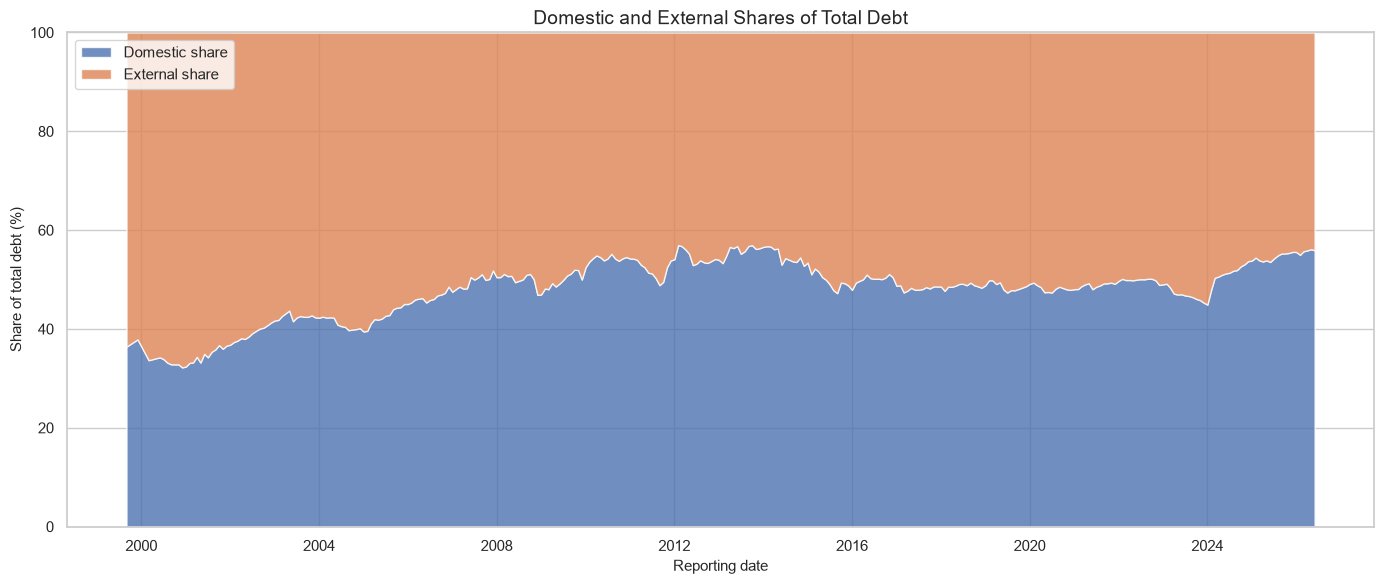

In [12]:
# Graph 4: 100% stacked area chart
plot_df = df.dropna(subset=["domestic_share", "external_share"]).sort_values("date")
fig, ax = plt.subplots()
ax.stackplot(plot_df["date"], plot_df["domestic_share"], plot_df["external_share"],
             labels=["Domestic share", "External share"], alpha=0.8)
ax.set(title="Domestic and External Shares of Total Debt", xlabel="Reporting date", ylabel="Share of total debt (%)", ylim=(0, 100))
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

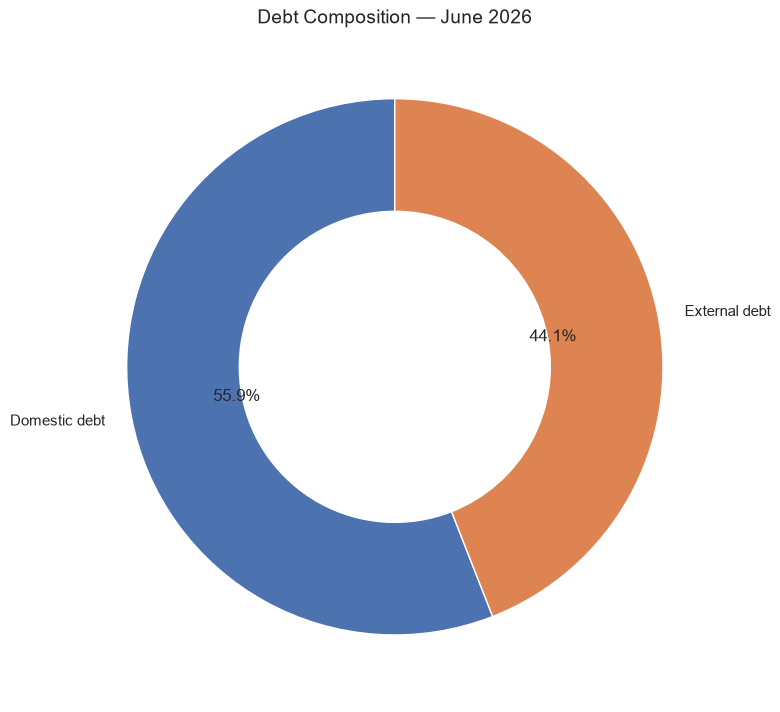

In [13]:
# Graph 5: Latest debt composition donut
latest_valid = df.dropna(subset=["domestic", "external"]).iloc[-1]
values = [latest_valid["domestic"], latest_valid["external"]]
labels = ["Domestic debt", "External debt"]
fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(values, labels=labels, autopct="%1.1f%%", startangle=90,
       wedgeprops={"width": 0.42})
ax.set_title(f"Debt Composition — {latest_valid['date']:%B %Y}")
plt.tight_layout()
plt.show()

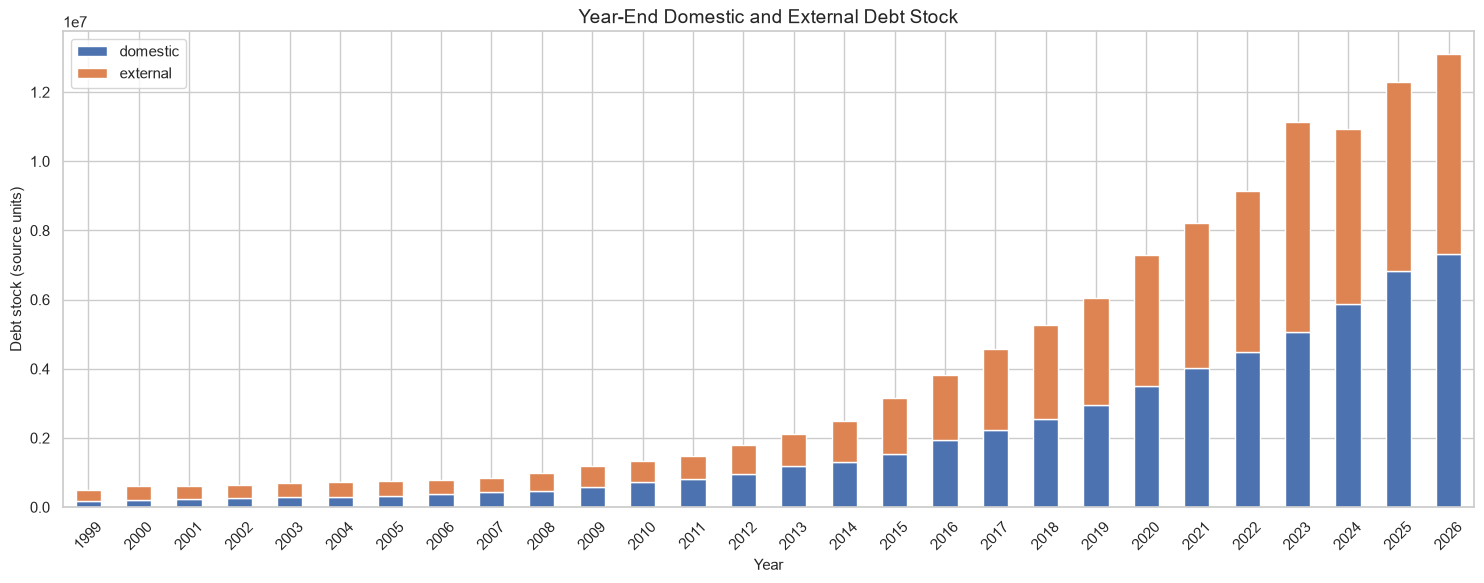

In [14]:
# Graph 6: Year-end domestic and external debt (last available observation per year)
annual = df.dropna(subset=["domestic", "external"]).groupby("year").tail(1).sort_values("year")
ax = annual.set_index("year")[["domestic", "external"]].plot(kind="bar", stacked=True, figsize=(15, 6))
ax.set(title="Year-End Domestic and External Debt Stock", xlabel="Year", ylabel="Debt stock (source units)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

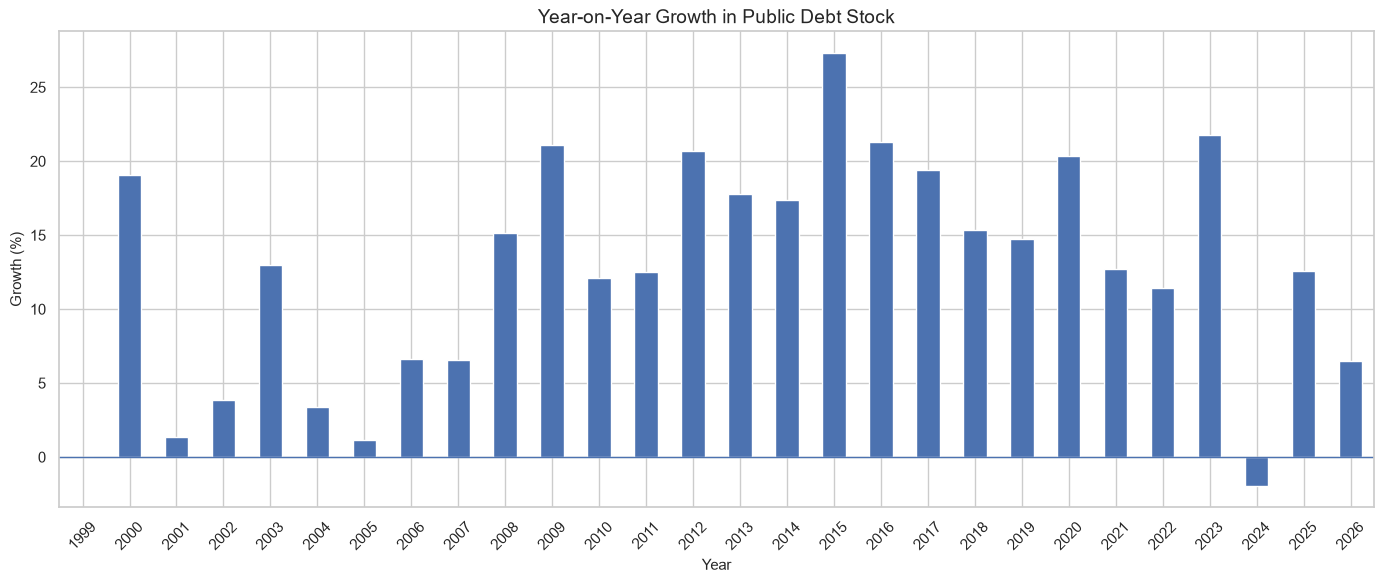

In [15]:
# Graph 7: Year-on-year growth in total debt stock
annual_total = df.dropna(subset=["total"]).groupby("year").tail(1).set_index("year")["total"].sort_index()
annual_growth = annual_total.pct_change(fill_method=None) * 100
fig, ax = plt.subplots()
annual_growth.plot(kind="bar", ax=ax)
ax.axhline(0, linewidth=1)
ax.set(title="Year-on-Year Growth in Public Debt Stock", xlabel="Year", ylabel="Growth (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

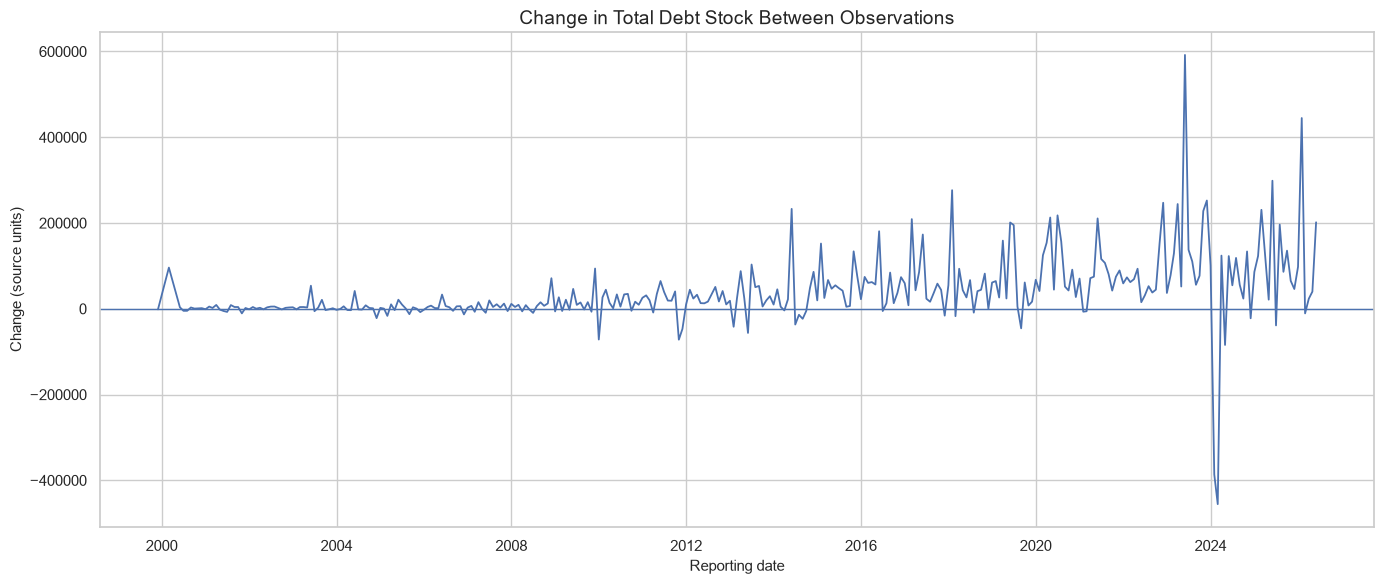

In [16]:
# Graph 8: Change in total debt stock between reported observations
fig, ax = plt.subplots()
ax.plot(df["date"], df["total_change"], linewidth=1.3)
ax.axhline(0, linewidth=1)
ax.set(title="Change in Total Debt Stock Between Observations", xlabel="Reporting date", ylabel="Change (source units)")
plt.tight_layout()
plt.show()

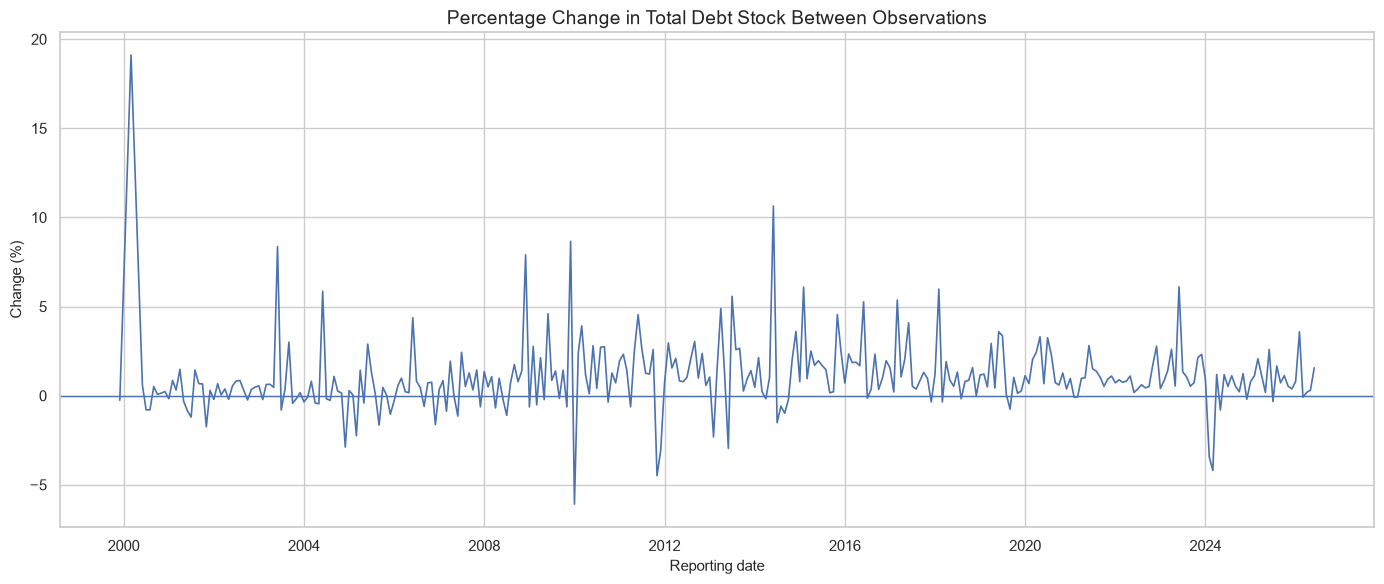

In [17]:
# Graph 9: Percentage change between reported observations
fig, ax = plt.subplots()
ax.plot(df["date"], df["debt_growth_rate"], linewidth=1.2)
ax.axhline(0, linewidth=1)
ax.set(title="Percentage Change in Total Debt Stock Between Observations", xlabel="Reporting date", ylabel="Change (%)")
plt.tight_layout()
plt.show()

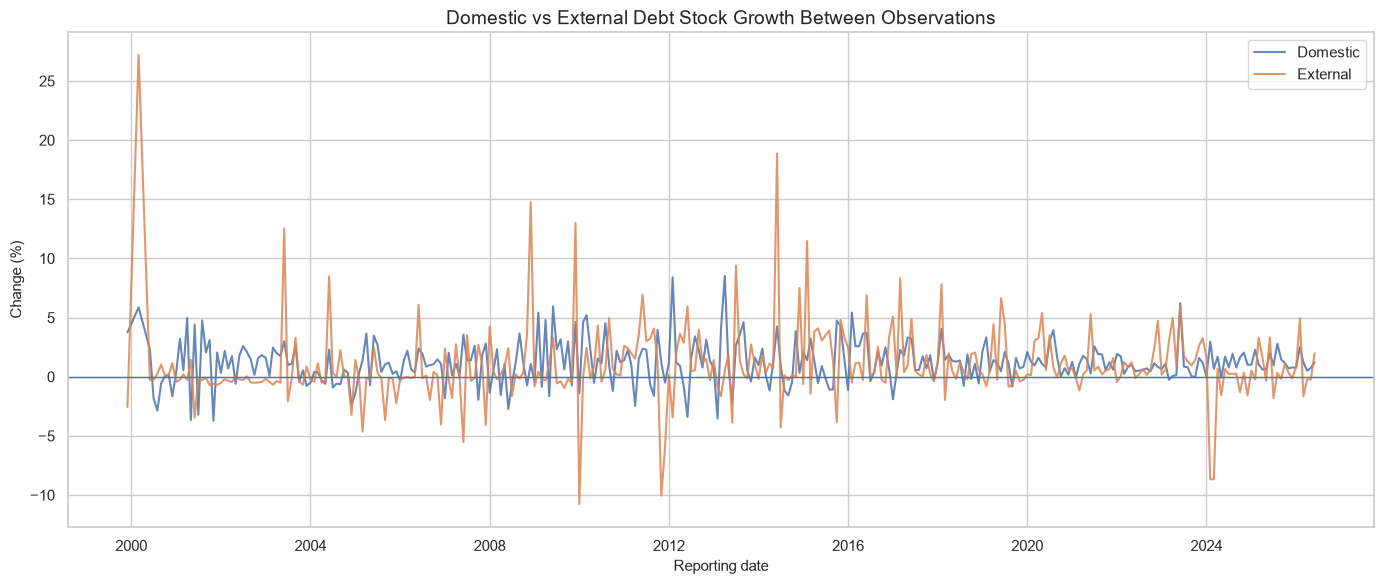

In [18]:
# Graph 10: Domestic vs external percentage changes
fig, ax = plt.subplots()
ax.plot(df["date"], df["domestic_growth"], label="Domestic", alpha=0.85)
ax.plot(df["date"], df["external_growth"], label="External", alpha=0.85)
ax.axhline(0, linewidth=1)
ax.set(title="Domestic vs External Debt Stock Growth Between Observations", xlabel="Reporting date", ylabel="Change (%)")
ax.legend()
plt.tight_layout()
plt.show()

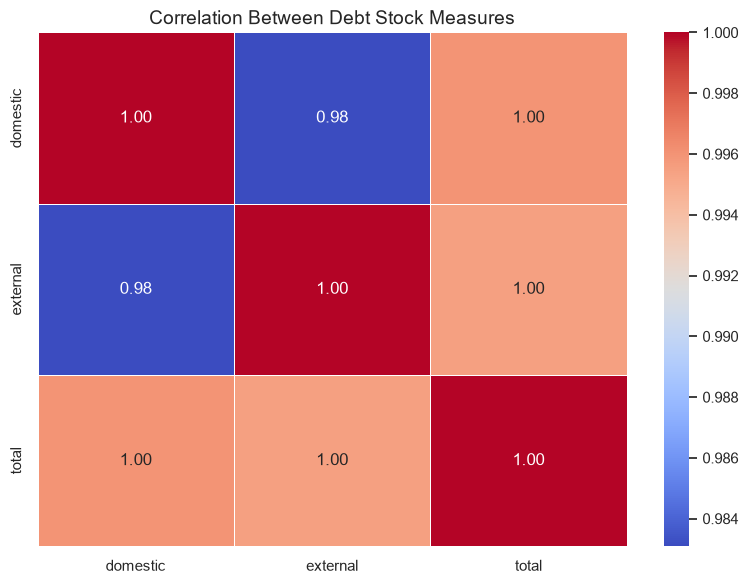

In [19]:
# Graph 11: Correlation heatmap (components and total are mathematically related)
corr = df[["domestic", "external", "total"]].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, ax=ax)
ax.set_title("Correlation Between Debt Stock Measures")
plt.tight_layout()
plt.show()

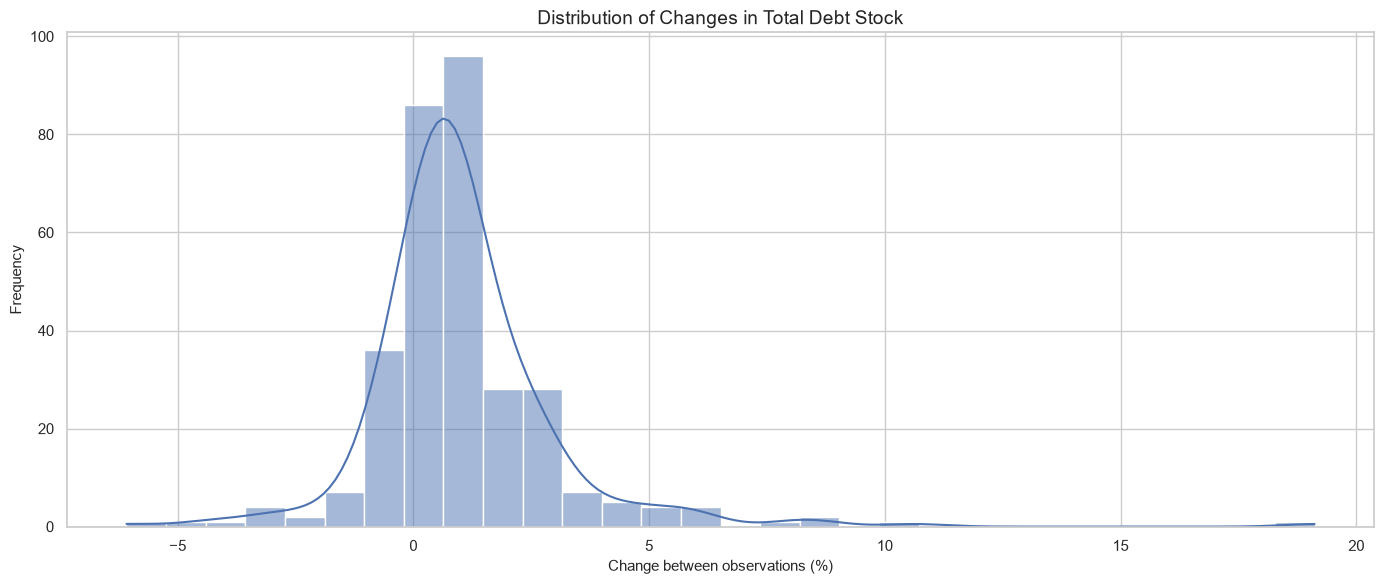

In [20]:
# Graph 12: Distribution of percentage changes between observations
growth_values = df["debt_growth_rate"].replace([np.inf, -np.inf], np.nan).dropna()
fig, ax = plt.subplots()
sns.histplot(growth_values, bins=30, kde=True, ax=ax)
ax.set(title="Distribution of Changes in Total Debt Stock", xlabel="Change between observations (%)", ylabel="Frequency")
plt.tight_layout()
plt.show()

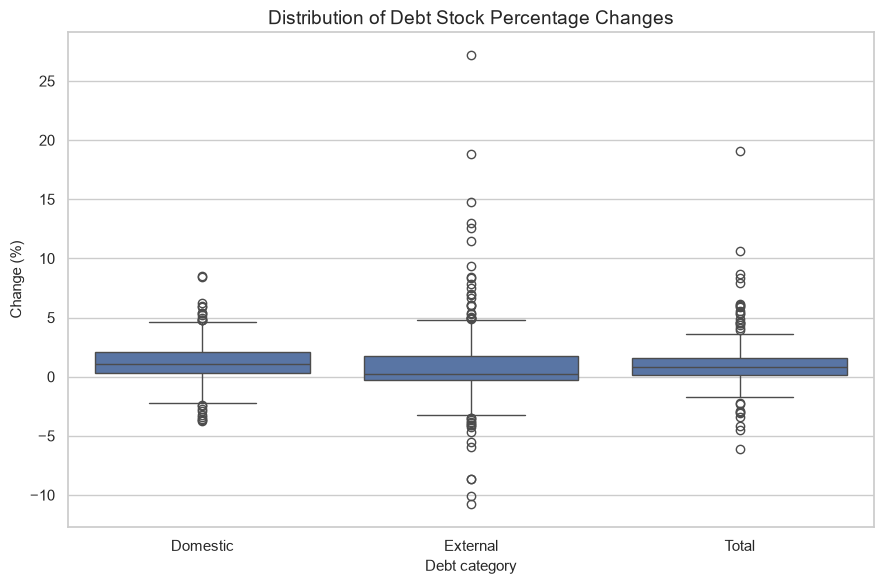

In [21]:
# Graph 13: Boxplot comparing debt growth rates
growth_long = df[["domestic_growth", "external_growth", "debt_growth_rate"]].rename(
    columns={"domestic_growth": "Domestic", "external_growth": "External", "debt_growth_rate": "Total"}
).melt(var_name="Debt category", value_name="Change (%)").replace([np.inf, -np.inf], np.nan).dropna()
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=growth_long, x="Debt category", y="Change (%)", ax=ax)
ax.set_title("Distribution of Debt Stock Percentage Changes")
plt.tight_layout()
plt.show()

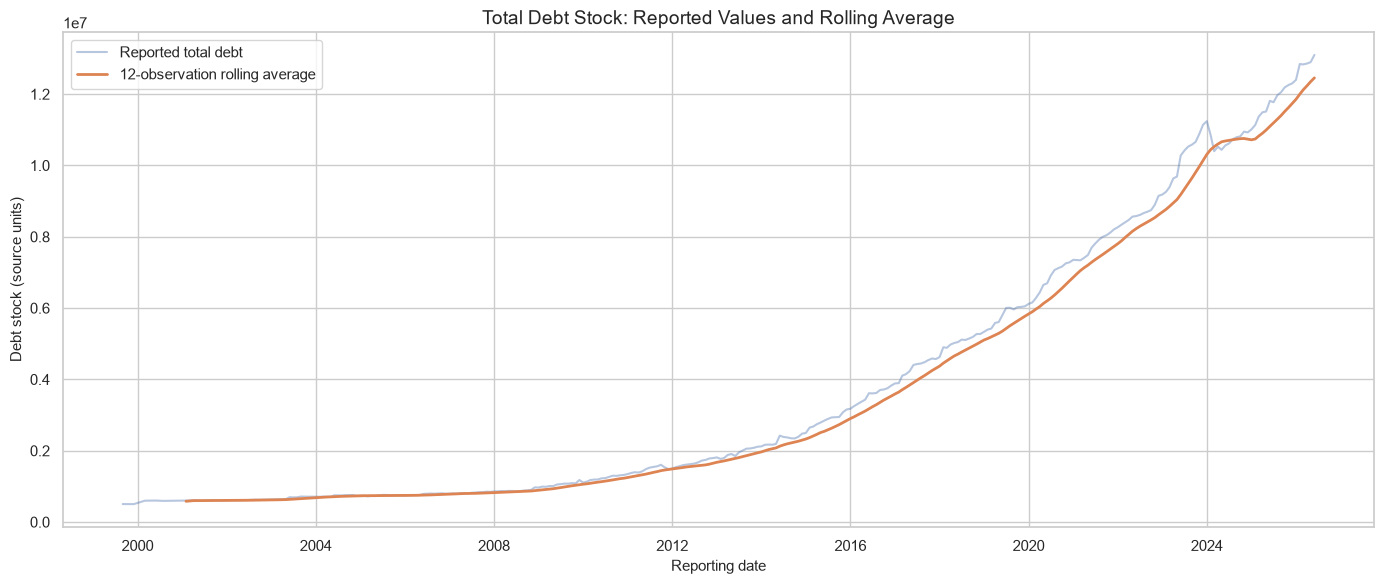

In [22]:
# Graph 14: Actual total debt and 12-observation rolling average
fig, ax = plt.subplots()
ax.plot(df["date"], df["total"], alpha=0.4, label="Reported total debt")
ax.plot(df["date"], df["rolling_12_observations"], linewidth=2, label="12-observation rolling average")
ax.set(title="Total Debt Stock: Reported Values and Rolling Average", xlabel="Reporting date", ylabel="Debt stock (source units)")
ax.legend()
plt.tight_layout()
plt.show()

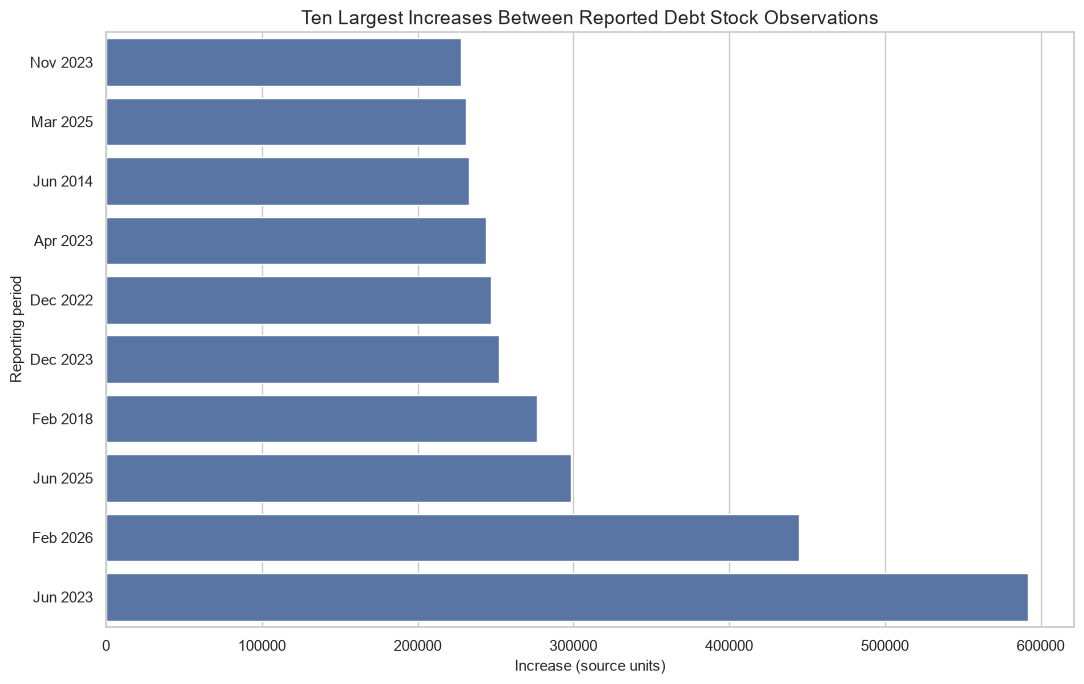

In [23]:
# Graph 15: Ten largest positive changes between reported observations
top_increases = df.nlargest(10, "total_change").dropna(subset=["total_change"]).copy()
top_increases["period"] = top_increases["date"].dt.strftime("%b %Y")
top_increases = top_increases.sort_values("total_change")
fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(data=top_increases, x="total_change", y="period", ax=ax)
ax.set(title="Ten Largest Increases Between Reported Debt Stock Observations",
       xlabel="Increase (source units)", ylabel="Reporting period")
plt.tight_layout()
plt.show()

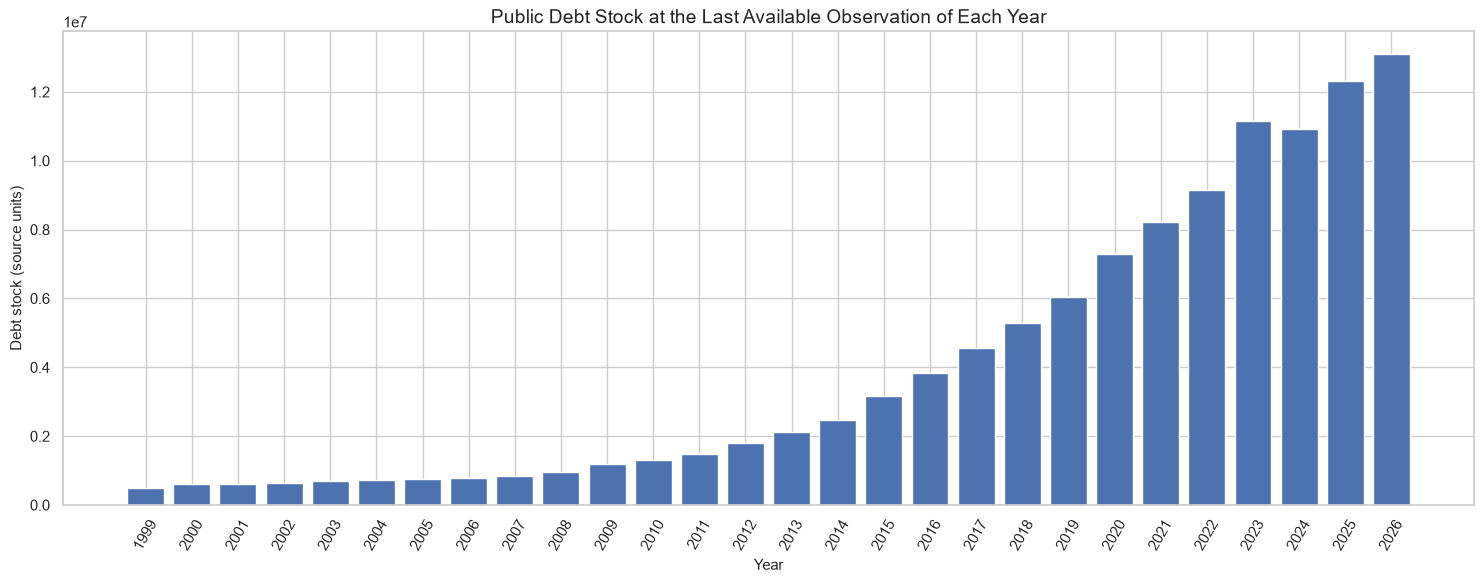

In [24]:
# Graph 16: Total debt stock at the last available observation in each year
year_end = df.dropna(subset=["total"]).groupby("year").tail(1).sort_values("year")
fig, ax = plt.subplots(figsize=(15, 6))
ax.bar(year_end["year"].astype(str), year_end["total"])
ax.set(title="Public Debt Stock at the Last Available Observation of Each Year",
       xlabel="Year", ylabel="Debt stock (source units)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

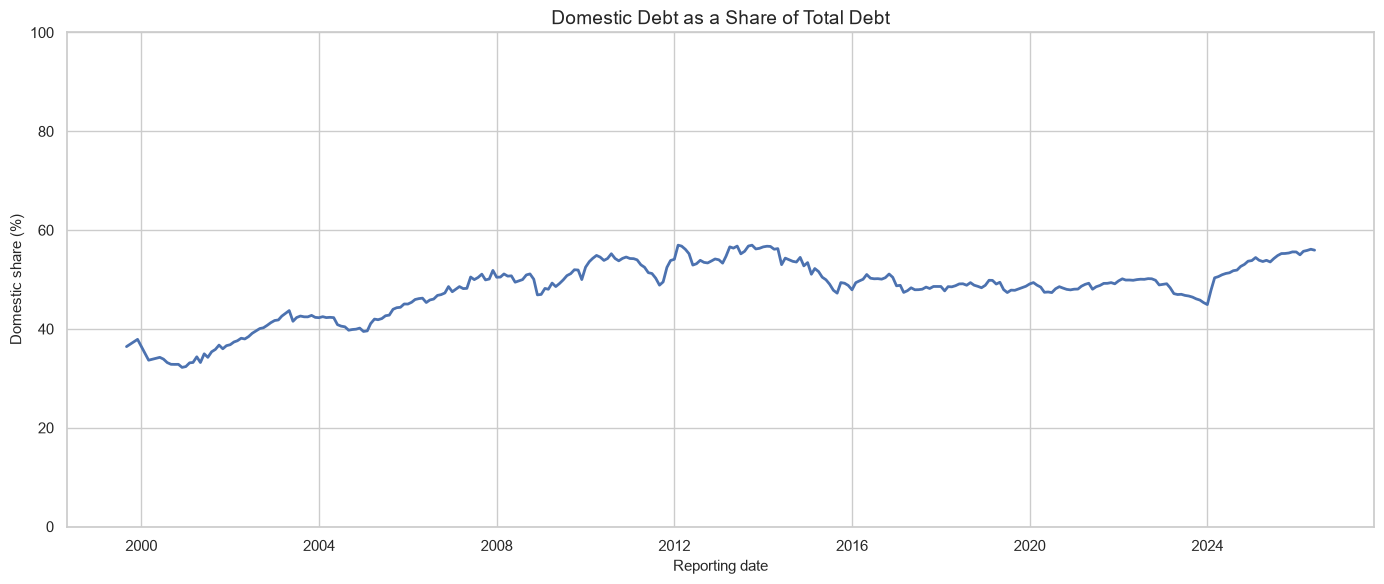

In [25]:
# Graph 17: Domestic debt share over time
fig, ax = plt.subplots()
ax.plot(df["date"], df["domestic_share"], linewidth=2)
ax.set(title="Domestic Debt as a Share of Total Debt", xlabel="Reporting date", ylabel="Domestic share (%)")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

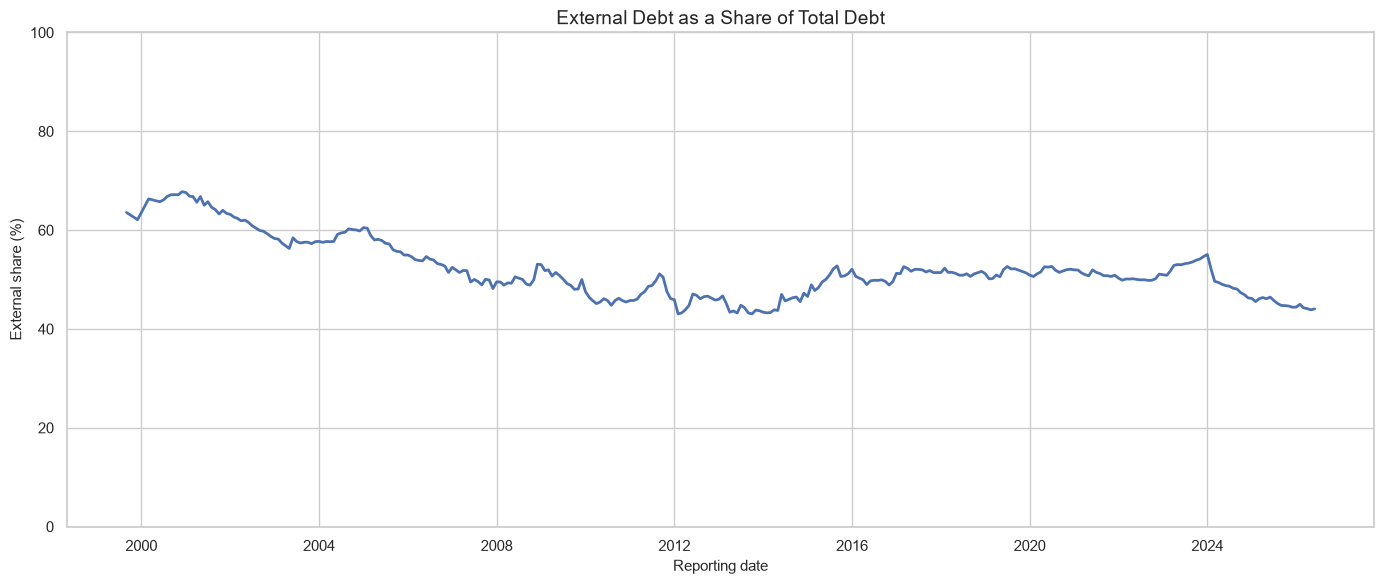

In [26]:
# Graph 18: External debt share over time
fig, ax = plt.subplots()
ax.plot(df["date"], df["external_share"], linewidth=2)
ax.set(title="External Debt as a Share of Total Debt", xlabel="Reporting date", ylabel="External share (%)")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

In [27]:
annual_summary = (
    df.dropna(subset=["total"])
      .groupby("year")
      .agg(
          domestic_debt=("domestic", "last"),
          external_debt=("external", "last"),
          total_debt=("total", "last"),
          observations=("total", "count")
      )
      .sort_index()
)
annual_summary["annual_growth_pct"] = annual_summary["total_debt"].pct_change(fill_method=None) * 100
annual_summary["domestic_share_pct"] = annual_summary["domestic_debt"] / annual_summary["total_debt"] * 100
annual_summary["external_share_pct"] = annual_summary["external_debt"] / annual_summary["total_debt"] * 100
display(annual_summary.tail(10))

,domestic_debt,external_debt,total_debt,observations,annual_growth_pct,domestic_share_pct,external_share_pct
year,,,,,,,
2017,2220345.35,2349284.44,4569629.79,12,19.395713,48.589174,51.410826
2018,2548768.78,2723734.27,5272503.04,12,15.381405,48.340774,51.659226
2019,2942103.54,3106822.96,6048926.50,12,14.725899,48.638441,51.361559
2020,3488541.18,3793285.24,7281826.42,12,20.382128,47.907503,52.092497
2021,4032368.18,4174371.53,8206739.71,12,12.701666,49.134837,50.865163
2022,4472838.52,4673144.13,9145982.65,12,11.444776,48.904953,51.095047
2023,5050108.54,6089584.98,11139693.52,12,21.798761,45.334358,54.665642
2024,5868273.16,5057005.78,10925278.94,12,-1.924780,53.712799,46.287201
2025,6838663.95,5461965.65,12300629.60,12,12.588701,55.596048,44.403952


In [28]:
annual_summary = (
    df.dropna(subset=["total"])
      .groupby("year")
      .agg(
          domestic_debt=("domestic", "last"),
          external_debt=("external", "last"),
          total_debt=("total", "last"),
          observations=("total", "count")
      )
      .sort_index()
)
annual_summary["annual_growth_pct"] = annual_summary["total_debt"].pct_change(fill_method=None) * 100
annual_summary["domestic_share_pct"] = annual_summary["domestic_debt"] / annual_summary["total_debt"] * 100
annual_summary["external_share_pct"] = annual_summary["external_debt"] / annual_summary["total_debt"] * 100
display(annual_summary.tail(10))

,domestic_debt,external_debt,total_debt,observations,annual_growth_pct,domestic_share_pct,external_share_pct
year,,,,,,,
2017,2220345.35,2349284.44,4569629.79,12,19.395713,48.589174,51.410826
2018,2548768.78,2723734.27,5272503.04,12,15.381405,48.340774,51.659226
2019,2942103.54,3106822.96,6048926.50,12,14.725899,48.638441,51.361559
2020,3488541.18,3793285.24,7281826.42,12,20.382128,47.907503,52.092497
2021,4032368.18,4174371.53,8206739.71,12,12.701666,49.134837,50.865163
2022,4472838.52,4673144.13,9145982.65,12,11.444776,48.904953,51.095047
2023,5050108.54,6089584.98,11139693.52,12,21.798761,45.334358,54.665642
2024,5868273.16,5057005.78,10925278.94,12,-1.924780,53.712799,46.287201
2025,6838663.95,5461965.65,12300629.60,12,12.588701,55.596048,44.403952


In [29]:
# Largest increases and decreases between consecutive observations.
changes = df.dropna(subset=["total_change"]).copy()

print("Largest increases:")
display(changes.nlargest(5, "total_change")[["date", "total_change", "total", "domestic", "external"]])

print("Largest decreases:")
display(changes.nsmallest(5, "total_change")[["date", "total_change", "total", "domestic", "external"]])

print("Highest percentage increases:")
display(df.replace([np.inf, -np.inf], np.nan).nlargest(5, "debt_growth_rate")[
    ["date", "debt_growth_rate", "total"]
])

Largest increases:


,date,total_change,total,domestic,external
279,2023-06-01,591863.87,10278672.99,4832112.06,5446560.94
311,2026-02-01,444733.26,12843193.11,7064119.63,5779073.48
303,2025-06-01,298567.55,11810283.92,6325454.27,5484829.65
215,2018-02-01,276470.27,4901287.76,2338213.71,2563074.05
285,2023-12-01,252440.47,11139693.52,5050108.54,6089584.98


Largest decreases:


,date,total_change,total,domestic,external
288,2024-03-01,-455493.33,10398611.75,5235188.41,5163423.34
287,2024-02-01,-386304.39,10854105.08,5200211.07,5653894.01
290,2024-05-01,-84330.72,10438194.05,5319887.46,5118306.60
140,2011-11-01,-72037.57,1532539.59,803894.34,728645.25
118,2010-01-01,-71666.41,1106274.22,580721.47,525552.75


Highest percentage increases:


,date,debt_growth_rate,total
2,2000-03-01,19.115908,598263.22
171,2014-06-01,10.634904,2422832.25
117,2009-12-01,8.650147,1177940.63
39,2003-06-01,8.366753,696429.97
105,2008-12-01,7.903239,972899.25
